# Compare GRU vs GRU-hybrid models

Run this after training some/all of: `gru.ipynb`, `gru_lstm.ipynb`, `gru_cnn.ipynb`, `gru_bilstm.ipynb`, `gru_resnet.ipynb`. It reads every `results/*.json` it finds and builds a comparison table + charts.

In [1]:
import glob
import json
import os

import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

RESULTS_DIR = os.path.join(os.getcwd(), "results")


In [2]:
rows = []
histories = {}
for path in glob.glob(os.path.join(RESULTS_DIR, "*.json")):
    with open(path) as f:
        data = json.load(f)
    rows.append({"model": data["model"], **data["metrics"]})
    histories[data["model"]] = data["history"]

if not rows:
    raise SystemExit(f"No results found in {RESULTS_DIR}. Train some models first.")

df = pd.DataFrame(rows).sort_values("f1_score", ascending=False).reset_index(drop=True)
df.to_csv(os.path.join(RESULTS_DIR, "comparison_table.csv"), index=False)
df


,model,loss,accuracy,precision,recall,f1_score
0,gru_bilstm,0.120229,0.954566,0.969361,0.942946,0.955971
1,gru,0.124918,0.953081,0.959587,0.950326,0.954934
2,gru_cnn,0.125285,0.953378,0.968467,0.941527,0.954807
3,gru_lstm,0.129038,0.952042,0.945434,0.963951,0.954603
4,gru_resnet,0.117860,0.951299,0.967242,0.938689,0.952751


## Accuracy / Precision / Recall / F1 across models

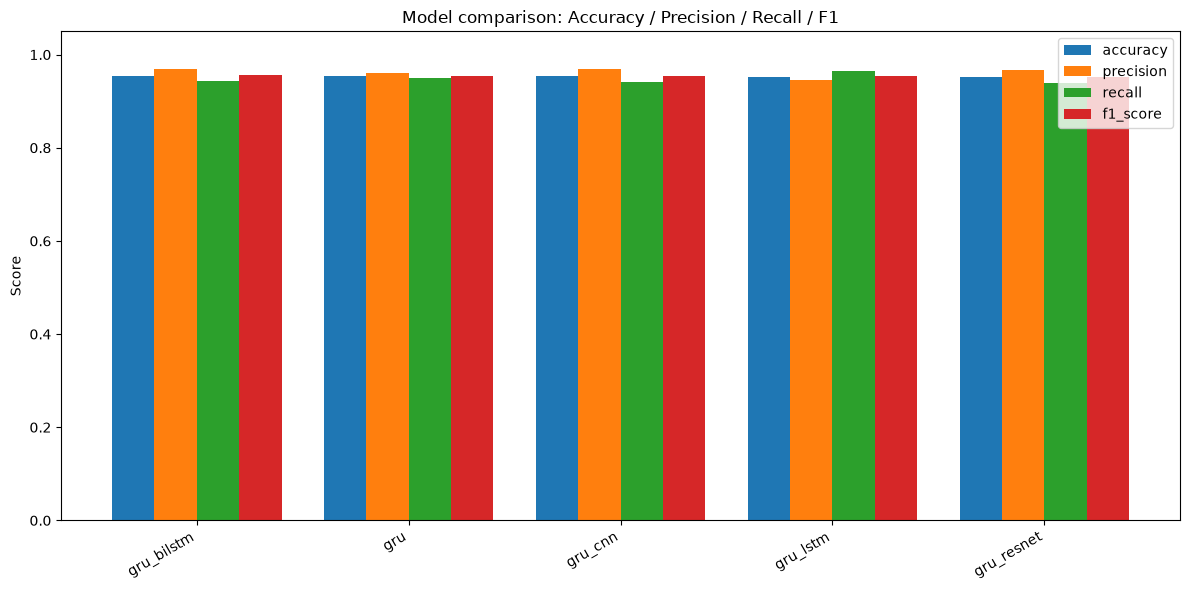

In [3]:
metrics = ["accuracy", "precision", "recall", "f1_score"]
x = range(len(df))
width = 0.2
fig, ax = plt.subplots(figsize=(12, 6))
for i, metric in enumerate(metrics):
    ax.bar([p + i * width for p in x], df[metric], width=width, label=metric)
ax.set_xticks([p + width * 1.5 for p in x])
ax.set_xticklabels(df["model"], rotation=30, ha="right")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Model comparison: Accuracy / Precision / Recall / F1")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "comparison_metrics.png"), dpi=150)
plt.show()


## Validation loss curves

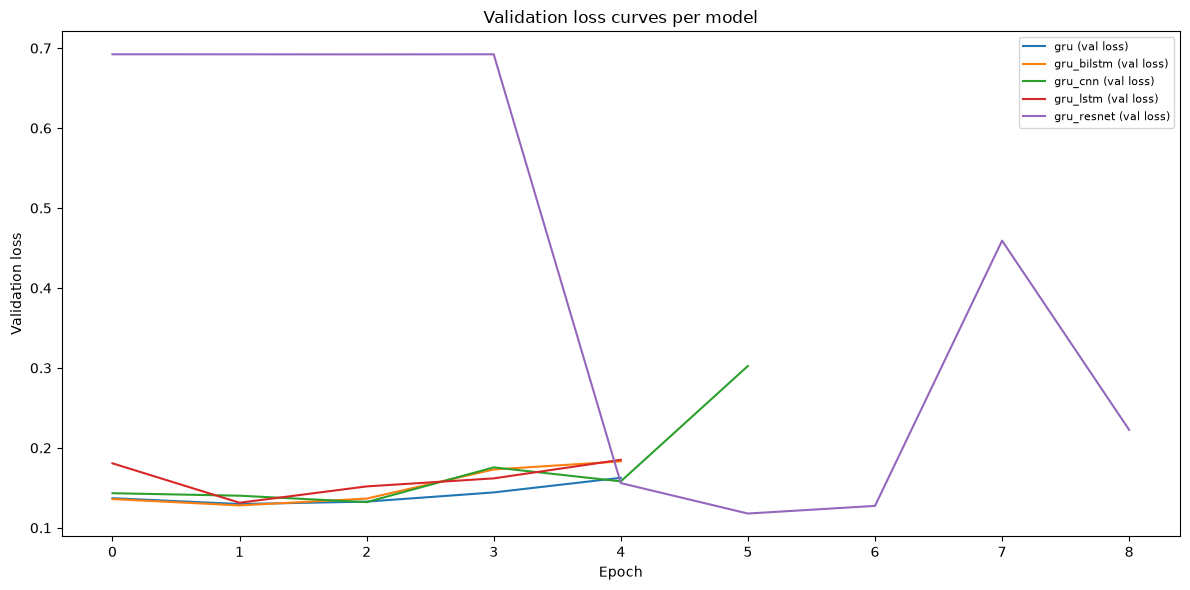

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
for name, hist in histories.items():
    if "val_loss" in hist:
        ax.plot(hist["val_loss"], label=f"{name} (val loss)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss")
ax.set_title("Validation loss curves per model")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "loss_curves.png"), dpi=150)
plt.show()


## GRU (alone) vs every GRU-hybrid combo

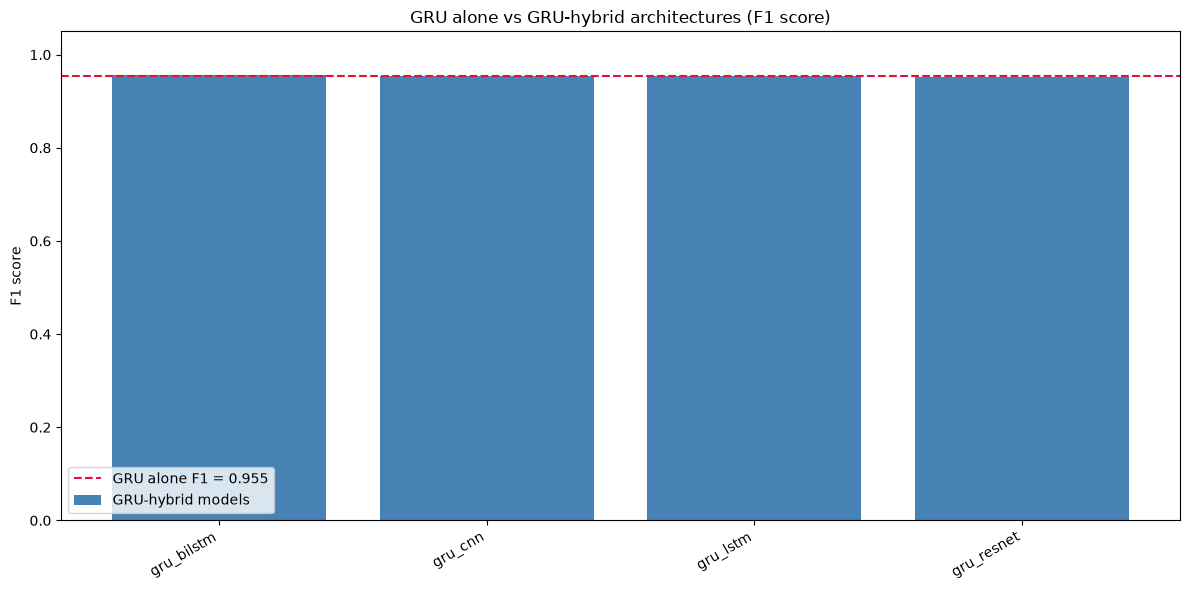

In [5]:
if "gru" in df["model"].values:
    gru_row = df[df["model"] == "gru"].iloc[0]
    others = df[df["model"] != "gru"]
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(range(len(others)), others["f1_score"], color="steelblue", label="GRU-hybrid models")
    ax.axhline(gru_row["f1_score"], color="crimson", linestyle="--",
               label=f"GRU alone F1 = {gru_row['f1_score']:.3f}")
    ax.set_xticks(range(len(others)))
    ax.set_xticklabels(others["model"], rotation=30, ha="right")
    ax.set_ylabel("F1 score")
    ax.set_ylim(0, 1.05)
    ax.set_title("GRU alone vs GRU-hybrid architectures (F1 score)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(RESULTS_DIR, "gru_vs_others.png"), dpi=150)
    plt.show()
else:
    print("No gru.json found yet -- run gru.ipynb first to include the GRU baseline.")


## Export PDF report

In [6]:
from matplotlib.backends.backend_pdf import PdfPages

pdf_path = os.path.join(RESULTS_DIR, "results_report.pdf")

with PdfPages(pdf_path) as pdf:
    # Page 1: results table
    fig, ax = plt.subplots(figsize=(11, 2 + 0.4 * len(df)))
    ax.axis("off")
    ax.set_title("Fake News Detection -- GRU model comparison results", fontsize=14, pad=20)
    table_data = df.round(4)
    tbl = ax.table(
        cellText=table_data.values,
        colLabels=table_data.columns,
        cellLoc="center",
        loc="center",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.8)
    pdf.savefig(fig)
    plt.close(fig)

    # Pages 2-4: the charts already saved as PNGs
    for chart_name, title in [
        ("comparison_metrics.png", "Accuracy / Precision / Recall / F1 across models"),
        ("loss_curves.png", "Validation loss curves per model"),
        ("gru_vs_others.png", "GRU alone vs GRU-hybrid architectures"),
    ]:
        chart_path = os.path.join(RESULTS_DIR, chart_name)
        if os.path.exists(chart_path):
            img = plt.imread(chart_path)
            fig, ax = plt.subplots(figsize=(11, 6))
            ax.imshow(img)
            ax.axis("off")
            ax.set_title(title, fontsize=12)
            pdf.savefig(fig)
            plt.close(fig)

print("Saved PDF report to", pdf_path)


Saved PDF report to C:\Users\ARKNOX\Documents\m.tech\experiments\results\results_report.pdf
